# MMA3001 Dataset 3 — Four-Class YOLO Object Detection

The dataset audit identified only six independent source images for the `wrinkle` class. This is insufficient to support reliable training, validation and testing of wrinkle detection.

The primary quantitative model is therefore restricted to four sufficiently supported defect classes:

- loose-meat
- packaging-error
- twisted-meat
- unsealed

Wrinkle images are removed from the four-class dataset rather than treated as background, because retaining visible wrinkle defects with empty labels would incorrectly teach the detector that wrinkles are background regions.

The original five-class dataset is preserved unchanged.

In [9]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
from pathlib import Path

source_root = Path(
    "/content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_clean"
)

four_class_root = Path(
    "/content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class"
)

print("Source exists:", source_root.exists())

Source exists: True


In [11]:
import shutil

if four_class_root.exists():
    print("Four-class dataset already exists.")
else:
    shutil.copytree(
        source_root,
        four_class_root
    )

    print("Four-class dataset created.")

Four-class dataset already exists.


In [4]:
image_extensions = [
    ".jpg",
    ".jpeg",
    ".png",
    ".webp"
]

removed = {
    "train": 0,
    "valid": 0,
    "test": 0
}

for split in ["train", "valid", "test"]:

    labels_dir = four_class_root / split / "labels"
    images_dir = four_class_root / split / "images"

    for label_path in list(labels_dir.glob("*.txt")):

        text = label_path.read_text().strip()

        if not text:
            continue

        class_ids = [
            int(line.split()[0])
            for line in text.splitlines()
        ]

        if 4 in class_ids:

            # Remove matching image
            for ext in image_extensions:
                image_path = images_dir / (
                    label_path.stem + ext
                )

                if image_path.exists():
                    image_path.unlink()
                    break

            # Remove annotation
            label_path.unlink()

            removed[split] += 1

print("Removed wrinkle images:")
print(removed)

Removed wrinkle images:
{'train': 0, 'valid': 0, 'test': 0}


In [5]:
for split in ["train", "valid", "test"]:

    images_dir = four_class_root / split / "images"
    labels_dir = four_class_root / split / "labels"

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in image_extensions
    ]

    labels = list(
        labels_dir.glob("*.txt")
    )

    print(
        f"{split:5s} | "
        f"images = {len(images)} | "
        f"labels = {len(labels)}"
    )

train | images = 3138 | labels = 3331
valid | images = 120 | labels = 120
test  | images = 80 | labels = 80


In [6]:
remaining_wrinkle = []

for split in ["train", "valid", "test"]:

    labels_dir = four_class_root / split / "labels"

    for label_path in labels_dir.glob("*.txt"):

        text = label_path.read_text().strip()

        if not text:
            continue

        for line in text.splitlines():

            class_id = int(
                line.split()[0]
            )

            if class_id == 4:
                remaining_wrinkle.append(
                    (split, label_path.name)
                )

print(
    "Remaining class-4 annotations:",
    len(remaining_wrinkle)
)

Remaining class-4 annotations: 0


In [14]:
import yaml

yaml_path_4class = (
    four_class_root / "data.yaml"
)

config_4class = {
    "path": str(four_class_root),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 4,
    "names": [
        "loose-meat",
        "packaging-error",
        "twisted-meat",
        "unsealed"
    ]
}

with open(
    yaml_path_4class,
    "w"
) as f:

    yaml.safe_dump(
        config_4class,
        f,
        sort_keys=False
    )

print(
    yaml_path_4class.read_text()
)

path: /content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class
train: train/images
val: valid/images
test: test/images
nc: 4
names:
- loose-meat
- packaging-error
- twisted-meat
- unsealed



In [5]:
!pip install -q ultralytics
from ultralytics import YOLO
import torch

print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 10.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CUDA: True
GPU: Tesla T4


In [9]:
runs_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/model_runs"
)

model_4class = YOLO(
    "yolov8n.pt"
)

results_4class = model_4class.train(
    data=str(yaml_path_4class),
    epochs=30,
    imgsz=640,
    batch=16,
    seed=42,
    workers=0,
    project=str(runs_dir),
    name="yolov8n_4class_30epochs",
    plots=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_4cl

In [15]:
from pathlib import Path
from ultralytics import YOLO

# Folder containing all model training runs
runs_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/model_runs"
)

# Find the best.pt file from the 4-class YOLO experiment.
# Using glob also handles cases where Ultralytics created
# a folder such as yolov8n_4class_30epochs-2.
candidates = sorted(
    runs_dir.glob(
        "yolov8n_4class_30epochs*/weights/best.pt"
    )
)

print("Checkpoints found:", len(candidates))

for path in candidates:
    print(path)

# Use the most recent matching training run
best_4class_path = candidates[-1]

print("\nUsing checkpoint:")
print(best_4class_path)

# Load the best validation checkpoint, rather than last.pt
best_model_4class = YOLO(best_4class_path)

Checkpoints found: 1
/content/drive/MyDrive/MMA3001_Project/model_runs/yolov8n_4class_30epochs/weights/best.pt

Using checkpoint:
/content/drive/MyDrive/MMA3001_Project/model_runs/yolov8n_4class_30epochs/weights/best.pt


In [16]:
# Evaluate using exactly the same 4-class dataset configuration
# used during training.
#
# split="val" ensures we are NOT touching the final test set yet.
# The test set should remain untouched until final model selection.

val_metrics_4class = best_model_4class.val(
    data=str(yaml_path_4class),
    split="val",
    imgsz=640,
    device=0,
    workers=0,
    plots=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.4 ms, read: 12.9±28.4 MB/s, size: 66.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class/valid/labels.cache... 120 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 18.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.5it/s 3.2s
                   all        120        121        0.7      0.566      0.519      0.306
            loose-meat          3          3      0.844      0.333      0.346      0.169
       packaging-error         23         34      0.454      0.412      0.366      0.123
          twisted-meat 

In [17]:
# Mean precision across the four defect classes
precision_4class = val_metrics_4class.box.mp

# Mean recall across the four defect classes
recall_4class = val_metrics_4class.box.mr

# Mean Average Precision using IoU = 0.50
map50_4class = val_metrics_4class.box.map50

# Mean Average Precision averaged over IoU thresholds
# from 0.50 to 0.95. This is the stricter overall metric.
map5095_4class = val_metrics_4class.box.map

print("4-Class YOLOv8n Validation Results")
print("----------------------------------")
print(f"Precision:   {precision_4class:.4f}")
print(f"Recall:      {recall_4class:.4f}")
print(f"mAP@50:      {map50_4class:.4f}")
print(f"mAP@50:95:   {map5095_4class:.4f}")

4-Class YOLOv8n Validation Results
----------------------------------
Precision:   0.6998
Recall:      0.5664
mAP@50:      0.5195
mAP@50:95:   0.3057


In [18]:
print("\nPer-class mAP@50:95")
print("--------------------")

# val_metrics_4class.box.maps contains one mAP@50:95
# value for each class in the dataset.
for class_id, class_name in best_model_4class.names.items():

    class_map = val_metrics_4class.box.maps[class_id]

    print(
        f"{class_name:20s} "
        f"{class_map:.4f}"
    )


Per-class mAP@50:95
--------------------
loose-meat           0.1686
packaging-error      0.1225
twisted-meat         0.2883
unsealed             0.6434


In [19]:
# Find all confusion matrices generated by validation
confusion_matrices = sorted(
    runs_dir.rglob("confusion_matrix.png"),
    key=lambda p: p.stat().st_mtime
)

latest_confusion_matrix = confusion_matrices[-1]

print("Showing:")
print(latest_confusion_matrix)

Showing:
/content/drive/MyDrive/MMA3001_Project/model_runs/yolov8n_4class_30epochs/confusion_matrix.png


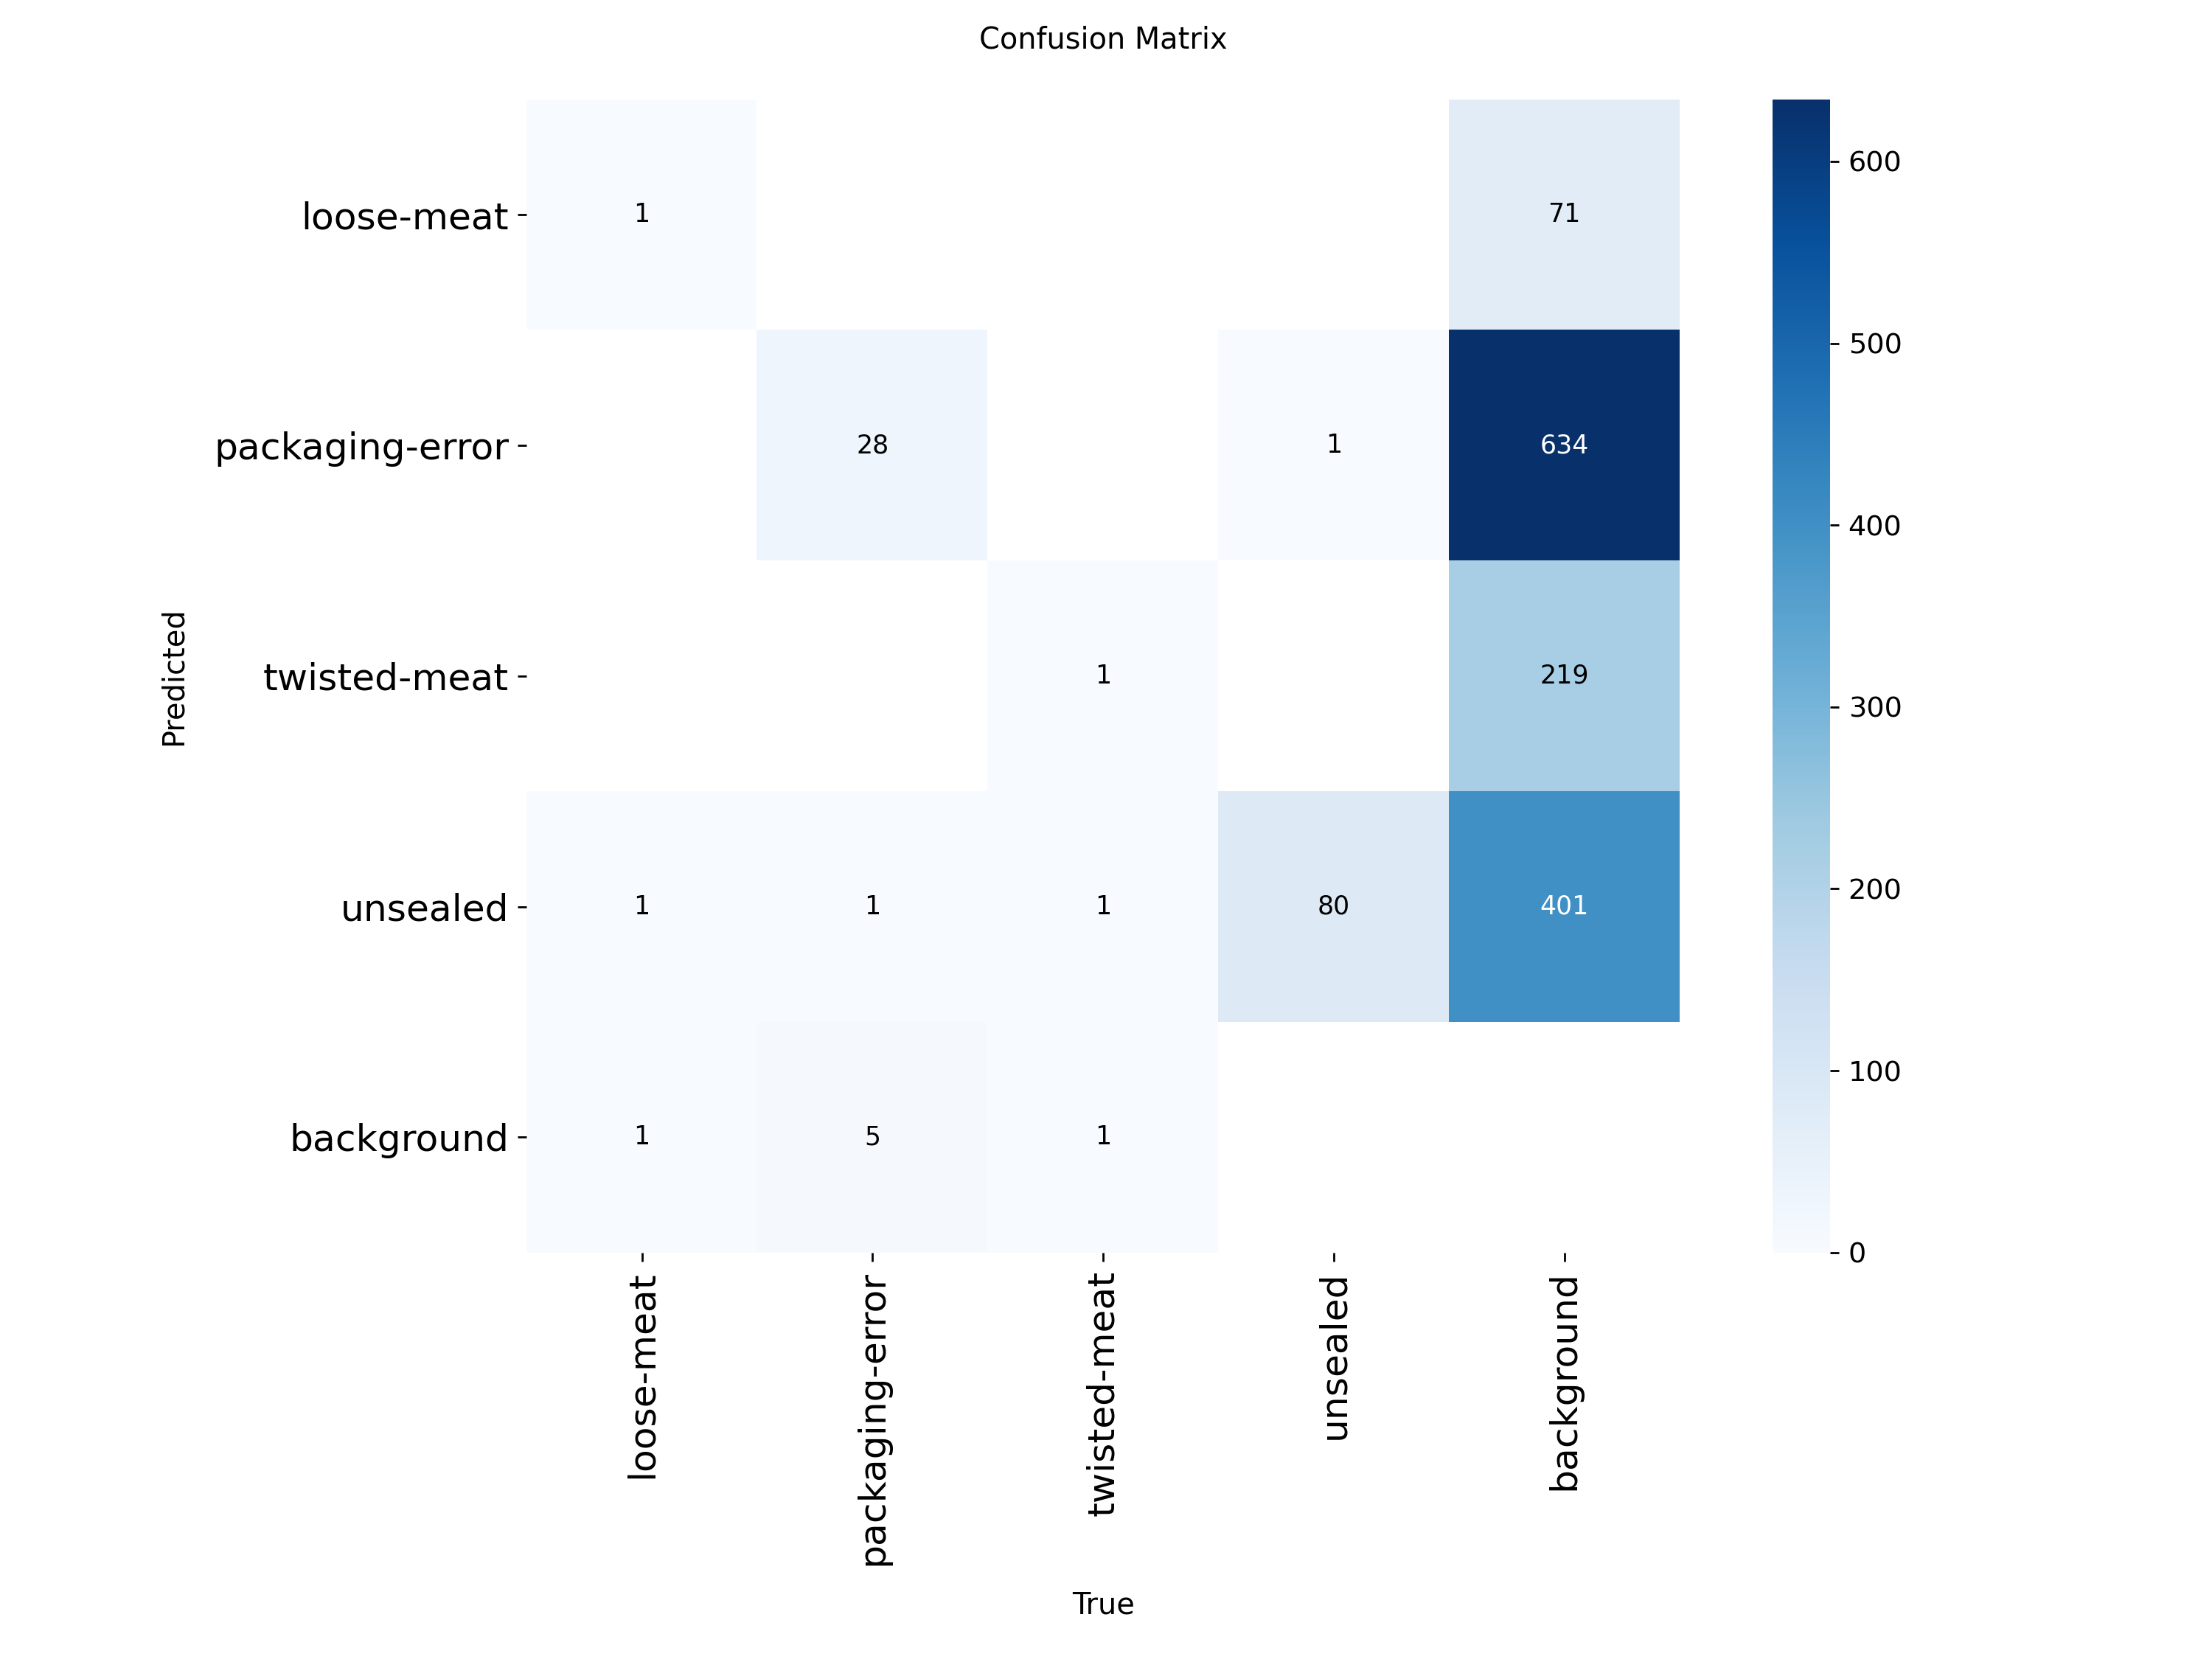

In [20]:
from PIL import Image
from IPython.display import display

display(
    Image.open(latest_confusion_matrix)
)

In [22]:

import torch
from pathlib import Path
from PIL import Image
from ultralytics import YOLO

# Four-class validation dataset
valid_images_dir = Path(four_class_root) / "valid" / "images"
valid_labels_dir = Path(four_class_root) / "valid" / "labels"

image_paths = sorted([
    p for p in valid_images_dir.iterdir()
    if p.suffix.lower() in
    [".jpg", ".jpeg", ".png", ".webp"]
])

print("Validation images:", len(image_paths))


# ---------------------------------------
# Load ground-truth annotations
# ---------------------------------------
def load_ground_truth(image_path):

    with Image.open(image_path) as img:
        width, height = img.size

    label_path = valid_labels_dir / (
        image_path.stem + ".txt"
    )

    boxes = []
    labels = []

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            if not line.strip():
                continue

            values = list(map(float, line.split()))

            class_id = int(values[0])
            xc, yc, bw, bh = values[1:5]

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            boxes.append([x1, y1, x2, y2])
            labels.append(class_id)

    return {
        "boxes": torch.tensor(
            boxes, dtype=torch.float32
        ).reshape(-1, 4),

        "labels": torch.tensor(
            labels, dtype=torch.int64
        )
    }


targets_all_4class = [
    load_ground_truth(p)
    for p in image_paths
]


# ---------------------------------------
# Collect predictions from trained YOLO
# ---------------------------------------
predictions_all_4class = []

results = best_model_4class.predict(
    source=[str(p) for p in image_paths],
    imgsz=640,
    conf=0.001,
    iou=0.70,
    max_det=300,
    device=0,
    stream=True,
    verbose=False
)

for result in results:

    boxes = result.boxes

    predictions_all_4class.append({
        "boxes": boxes.xyxy.detach().cpu(),
        "scores": boxes.conf.detach().cpu(),
        "labels": boxes.cls.detach().cpu().long()
    })


# ---------------------------------------
# Verify data
# ---------------------------------------
print("Ground-truth images:", len(targets_all_4class))
print("Prediction images:", len(predictions_all_4class))

assert len(predictions_all_4class) == len(targets_all_4class)
assert len(image_paths) > 0

print("Ready for confusion matrix evaluation!")


Validation images: 120
Ground-truth images: 120
Prediction images: 120
Ready for confusion matrix evaluation!


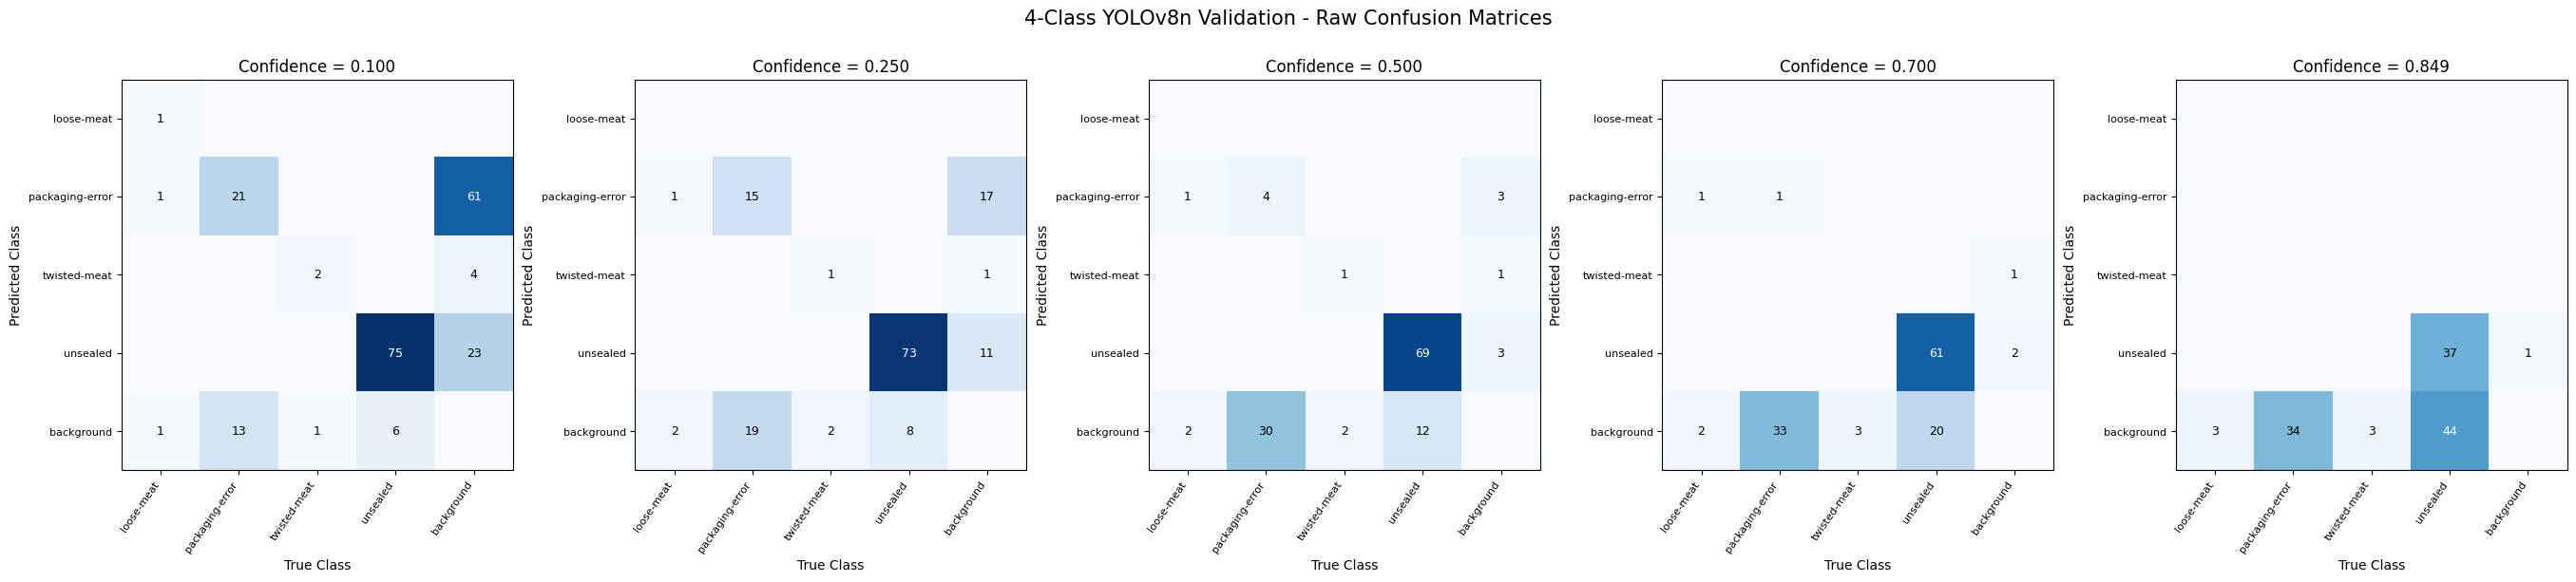

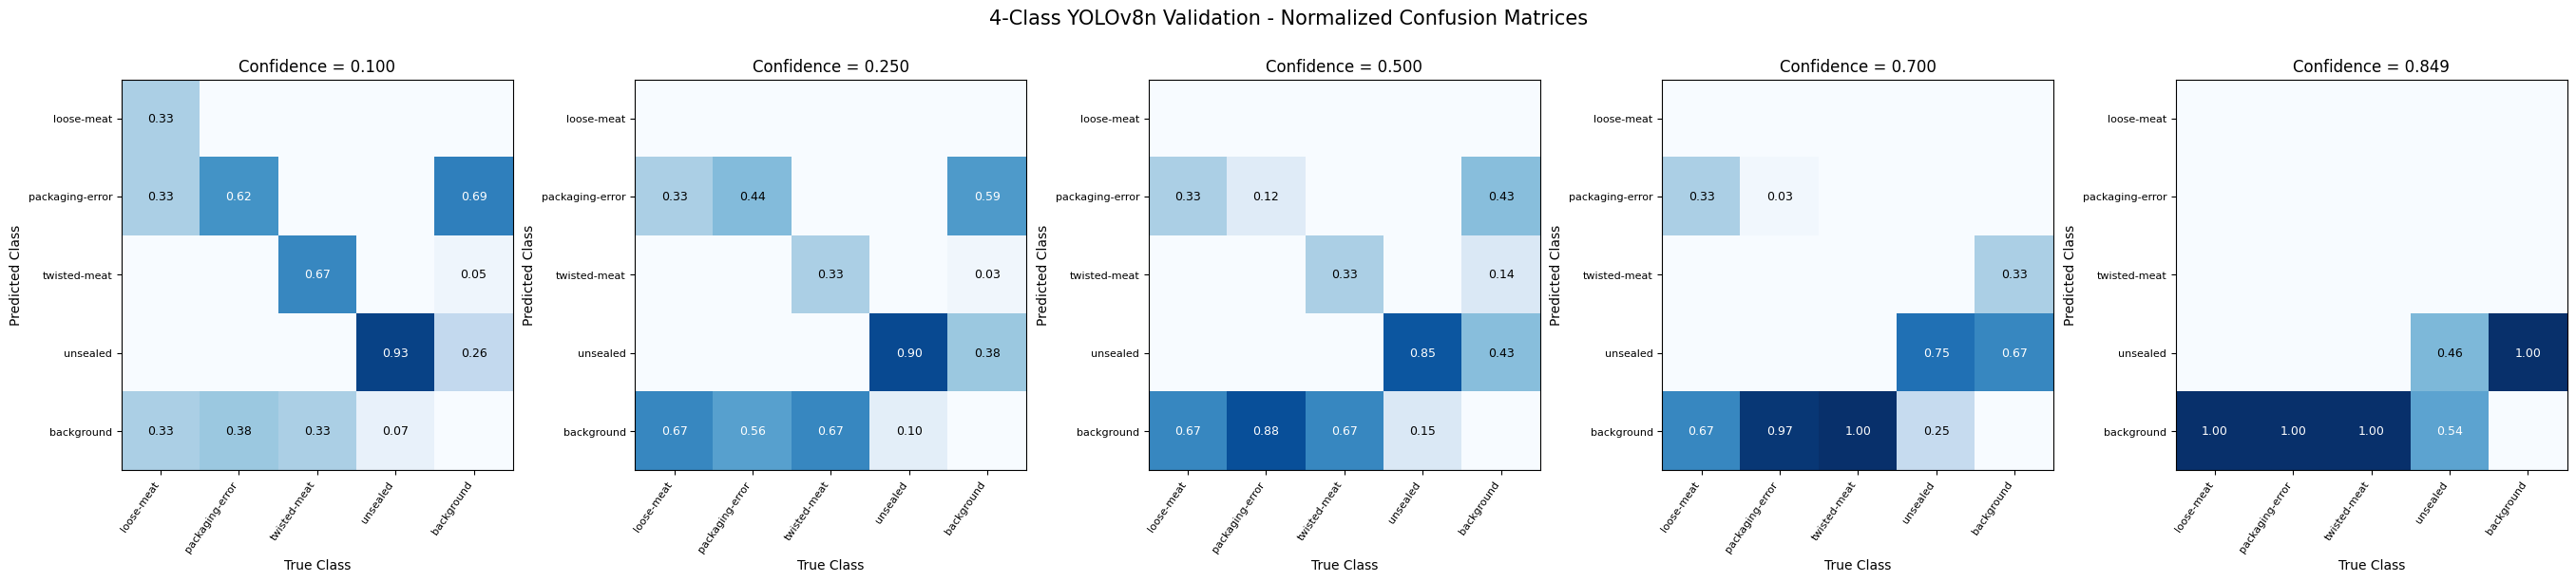


OVERALL THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.100,99,89,22,0.5266,0.8182,0.6408
1,0.250,89,30,32,0.7479,0.7355,0.7417
2,0.500,74,8,47,0.9024,0.6116,0.7291
3,0.700,62,4,59,0.9394,0.5124,0.6631
4,0.849,37,1,84,0.9737,0.3058,0.4654



CORRECT DETECTIONS BY CLASS


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,1,21,2,75
0.250,0,15,1,73
0.500,0,4,1,69
0.700,0,1,0,61
0.849,0,0,0,37



PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,0.3333,0.6176,0.6667,0.9259
0.250,0.0000,0.4412,0.3333,0.9012
0.500,0.0000,0.1176,0.3333,0.8519
0.700,0.0000,0.0294,0.0000,0.7531
0.849,0.0000,0.0000,0.0000,0.4568


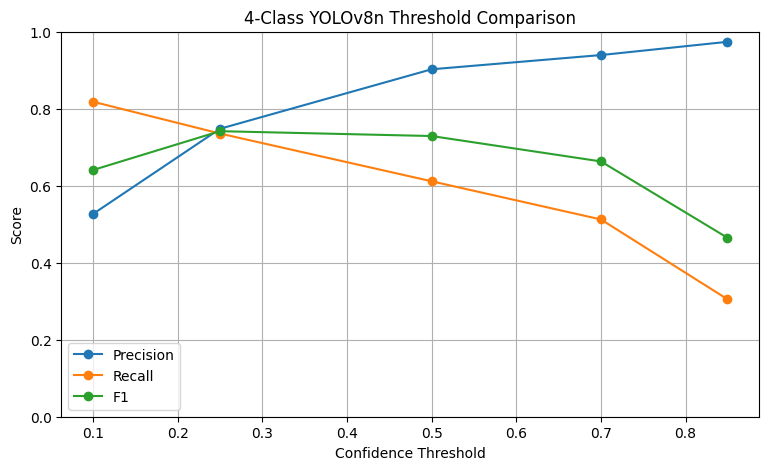

Best tested threshold: 0.250
Precision: 0.7479
Recall: 0.7355
F1: 0.7417


In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision.ops import box_iou

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

CLASS_NAMES = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed"
]

LABELS = CLASS_NAMES + ["background"]
N = len(CLASS_NAMES)


def make_confusion_matrix(threshold):
    cm = np.zeros((N + 1, N + 1), dtype=int)

    for pred, target in zip(
        predictions_all_4class,
        targets_all_4class
    ):
        keep = pred["scores"] >= threshold

        pboxes = pred["boxes"][keep].cpu()
        pscores = pred["scores"][keep].cpu()
        plabels = pred["labels"][keep].cpu()

        gboxes = target["boxes"].cpu()
        glabels = target["labels"].cpu()

        order = torch.argsort(
            pscores, descending=True
        )
        pboxes = pboxes[order]
        plabels = plabels[order]

        matched = set()

        for box, label in zip(pboxes, plabels):
            pred_cls = int(label)

            if len(gboxes) == 0:
                cm[pred_cls, N] += 1
                continue

            ious = box_iou(
                box.unsqueeze(0), gboxes
            )[0]

            for idx in matched:
                ious[idx] = -1

            best_iou, idx = ious.max(0)
            idx = int(idx)

            if best_iou >= IOU_THRESHOLD:
                true_cls = int(glabels[idx])
                cm[pred_cls, true_cls] += 1
                matched.add(idx)
            else:
                cm[pred_cls, N] += 1

        for idx, label in enumerate(glabels):
            if idx not in matched:
                cm[N, int(label)] += 1

    return cm


matrices = [
    make_confusion_matrix(t)
    for t in THRESHOLDS
]

# ---------------------------------------
# Plot raw confusion matrices
# ---------------------------------------
def plot_matrices(matrices, normalized=False):

    fig, axes = plt.subplots(
        1, len(THRESHOLDS),
        figsize=(27, 6),
        constrained_layout=True
    )

    vmax = 1.0 if normalized else max(
        cm.max() for cm in matrices
    )

    for ax, threshold, cm in zip(
        axes, THRESHOLDS, matrices
    ):
        if normalized:
            column_sums = cm.sum(axis=0, keepdims=True)
            data = np.divide(
                cm.astype(float),
                column_sums,
                out=np.zeros_like(cm, dtype=float),
                where=column_sums != 0
            )
        else:
            data = cm

        ax.imshow(
            data,
            cmap="Blues",
            vmin=0,
            vmax=vmax
        )

        ax.set_title(f"Confidence = {threshold:.3f}")
        ax.set_xticks(range(N + 1))
        ax.set_yticks(range(N + 1))
        ax.set_xticklabels(
            LABELS, rotation=55, ha="right",
            fontsize=8
        )
        ax.set_yticklabels(LABELS, fontsize=8)

        ax.set_xlabel("True Class")
        ax.set_ylabel("Predicted Class")

        for row in range(N + 1):
            for col in range(N + 1):
                value = data[row, col]

                if value > 0:
                    label = (
                        f"{value:.2f}"
                        if normalized
                        else str(value)
                    )

                    ax.text(
                        col, row, label,
                        ha="center", va="center",
                        fontsize=9,
                        color=(
                            "white"
                            if value > vmax * 0.5
                            else "black"
                        )
                    )

    title = (
        "Normalized Confusion Matrices"
        if normalized
        else "Raw Confusion Matrices"
    )

    fig.suptitle(
        f"4-Class YOLOv8n Validation - {title}",
        fontsize=15
    )
    plt.show()


plot_matrices(matrices, normalized=False)
plot_matrices(matrices, normalized=True)


# ---------------------------------------
# Precision, Recall, F1, TP, FP, FN
# ---------------------------------------
summary = []
per_class = []

for threshold, cm in zip(THRESHOLDS, matrices):

    tp = int(np.trace(cm[:N, :N]))
    fp = int(cm[:N, :].sum() - tp)
    fn = int(cm[:, :N].sum() - tp)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    summary.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

    for i, name in enumerate(CLASS_NAMES):
        class_tp = cm[i, i]
        class_fp = cm[i, :].sum() - class_tp
        class_fn = cm[:, i].sum() - class_tp

        per_class.append({
            "Threshold": threshold,
            "Class": name,
            "TP": class_tp,
            "FP": class_fp,
            "FN": class_fn,
            "Recall": (
                class_tp / (class_tp + class_fn)
                if class_tp + class_fn else 0
            )
        })

summary_df = pd.DataFrame(summary)
class_df = pd.DataFrame(per_class)

print("\nOVERALL THRESHOLD COMPARISON")
display(summary_df.round(4))

print("\nCORRECT DETECTIONS BY CLASS")
display(class_df.pivot(
    index="Threshold",
    columns="Class",
    values="TP"
))

print("\nPER-CLASS RECALL")
display(class_df.pivot(
    index="Threshold",
    columns="Class",
    values="Recall"
).round(4))


# ---------------------------------------
# Precision / Recall / F1 graph
# ---------------------------------------
plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1"]:
    plt.plot(
        summary_df["Threshold"],
        summary_df[metric],
        marker="o",
        label=metric
    )

plt.title("4-Class YOLOv8n Threshold Comparison")
plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()


# ---------------------------------------
# Best threshold among tested values
# ---------------------------------------
best = summary_df.loc[summary_df["F1"].idxmax()]

print(f"Best tested threshold: {best['Threshold']:.3f}")
print(f"Precision: {best['Precision']:.4f}")
print(f"Recall: {best['Recall']:.4f}")
print(f"F1: {best['F1']:.4f}")


FINE CONFIDENCE THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,Micro-F1,Macro-F1,Macro-Recall
0,0.100,99,89,22,0.5266,0.8182,0.6408,0.5354,0.6359
1,0.125,95,78,26,0.5491,0.7851,0.6463,0.5455,0.6107
2,0.150,95,61,26,0.6090,0.7851,0.6859,0.6015,0.6107
3,0.175,95,52,26,0.6463,0.7851,0.7090,0.6116,0.6107
4,0.200,94,47,27,0.6667,0.7769,0.7176,0.6161,0.6077
5,0.225,91,40,30,0.6947,0.7521,0.7222,0.4291,0.4336
6,0.250,89,30,32,0.7479,0.7355,0.7417,0.4332,0.4189
7,0.275,86,27,35,0.7611,0.7107,0.7350,0.4196,0.3969
8,0.300,86,24,35,0.7818,0.7107,0.7446,0.4243,0.3969
9,0.325,85,20,36,0.8095,0.7025,0.7522,0.4239,0.3895



BEST MICRO-F1 THRESHOLD
Threshold: 0.450
Precision: 0.8817
Recall: 0.6777
Micro-F1: 0.7664

BEST MACRO-F1 THRESHOLD
Threshold: 0.200
Macro-F1: 0.6161
Macro-Recall: 0.6077


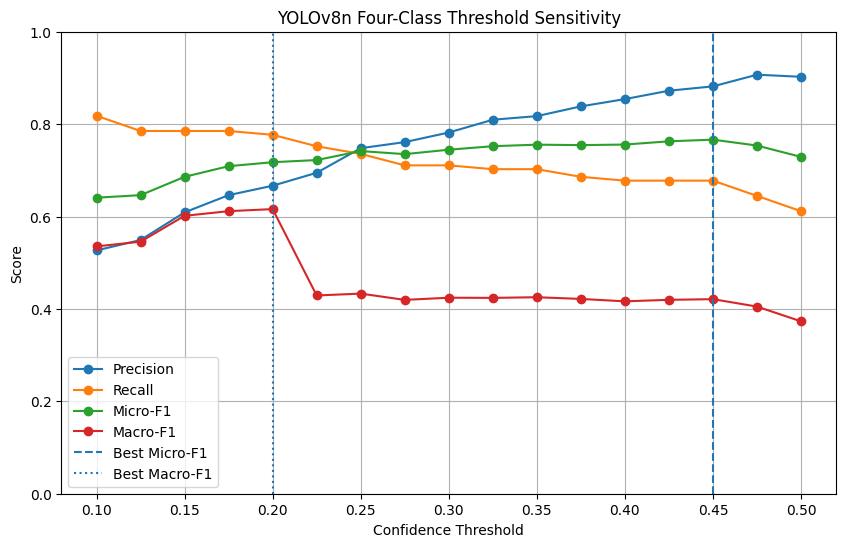


PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,0.3333,0.6176,0.6667,0.9259
0.125,0.3333,0.5294,0.6667,0.9136
0.150,0.3333,0.5294,0.6667,0.9136
0.175,0.3333,0.5294,0.6667,0.9136
0.200,0.3333,0.5294,0.6667,0.9012
0.225,0.0000,0.5000,0.3333,0.9012
0.250,0.0000,0.4412,0.3333,0.9012
0.275,0.0000,0.3529,0.3333,0.9012
0.300,0.0000,0.3529,0.3333,0.9012


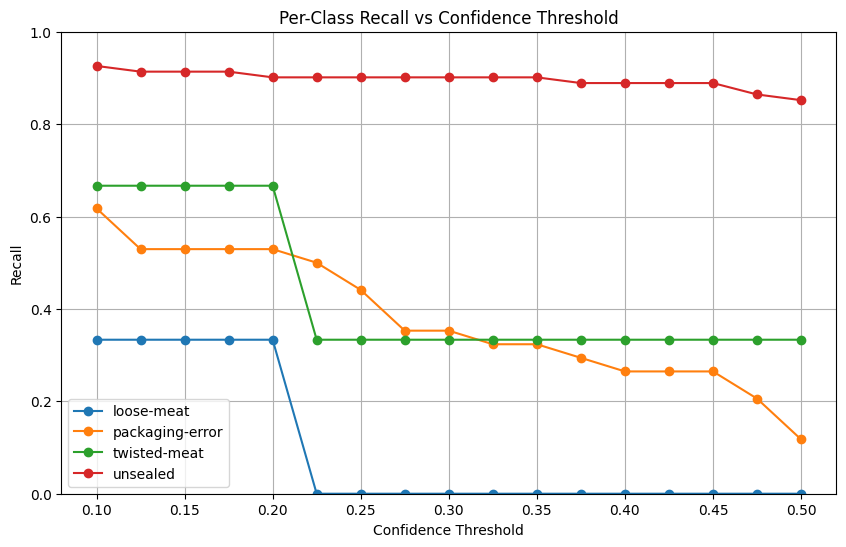


PER-CLASS PERFORMANCE AT SELECTED THRESHOLDS


,Threshold,Class,TP,FP,FN,Precision,Recall,F1
16,0.20,loose-meat,1,0,2,1.0000,0.3333,0.5000
17,0.20,packaging-error,18,31,16,0.3673,0.5294,0.4337
18,0.20,twisted-meat,2,1,1,0.6667,0.6667,0.6667
19,0.20,unsealed,73,15,8,0.8295,0.9012,0.8639
56,0.45,loose-meat,0,0,3,0.0000,0.0000,0.0000
57,0.45,packaging-error,9,6,25,0.6000,0.2647,0.3673
58,0.45,twisted-meat,1,1,2,0.5000,0.3333,0.4000
59,0.45,unsealed,72,4,9,0.9474,0.8889,0.9172


In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Finer confidence threshold sweep
FINE_THRESHOLDS = np.round(
    np.arange(0.10, 0.5001, 0.025), 3
)

CLASS_NAMES = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed"
]

N = len(CLASS_NAMES)

results = []
class_results = []

for threshold in FINE_THRESHOLDS:

    # Reuse your existing confusion matrix function
    cm = make_confusion_matrix(float(threshold))

    # Overall metrics
    tp = int(np.trace(cm[:N, :N]))
    fp = int(cm[:N, :].sum() - tp)
    fn = int(cm[:, :N].sum() - tp)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    micro_f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    class_f1_values = []
    class_recall_values = []

    for i, name in enumerate(CLASS_NAMES):

        class_tp = int(cm[i, i])
        class_fp = int(cm[i, :].sum() - class_tp)
        class_fn = int(cm[:, i].sum() - class_tp)

        class_precision = (
            class_tp / (class_tp + class_fp)
            if class_tp + class_fp else 0
        )

        class_recall = (
            class_tp / (class_tp + class_fn)
            if class_tp + class_fn else 0
        )

        class_f1 = (
            2 * class_precision * class_recall
            / (class_precision + class_recall)
            if class_precision + class_recall else 0
        )

        class_f1_values.append(class_f1)
        class_recall_values.append(class_recall)

        class_results.append({
            "Threshold": threshold,
            "Class": name,
            "TP": class_tp,
            "FP": class_fp,
            "FN": class_fn,
            "Precision": class_precision,
            "Recall": class_recall,
            "F1": class_f1
        })

    macro_f1 = np.mean(class_f1_values)
    macro_recall = np.mean(class_recall_values)

    results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "Micro-F1": micro_f1,
        "Macro-F1": macro_f1,
        "Macro-Recall": macro_recall
    })


# Convert results into DataFrames
fine_df = pd.DataFrame(results)
fine_class_df = pd.DataFrame(class_results)

print("FINE CONFIDENCE THRESHOLD COMPARISON")
display(fine_df.round(4))


# Find best operating points
best_micro = fine_df.loc[
    fine_df["Micro-F1"].idxmax()
]

best_macro = fine_df.loc[
    fine_df["Macro-F1"].idxmax()
]

print("\nBEST MICRO-F1 THRESHOLD")
print(f"Threshold: {best_micro['Threshold']:.3f}")
print(f"Precision: {best_micro['Precision']:.4f}")
print(f"Recall: {best_micro['Recall']:.4f}")
print(f"Micro-F1: {best_micro['Micro-F1']:.4f}")

print("\nBEST MACRO-F1 THRESHOLD")
print(f"Threshold: {best_macro['Threshold']:.3f}")
print(f"Macro-F1: {best_macro['Macro-F1']:.4f}")
print(f"Macro-Recall: {best_macro['Macro-Recall']:.4f}")


# Plot threshold sensitivity
plt.figure(figsize=(10, 6))

for metric in [
    "Precision", "Recall", "Micro-F1", "Macro-F1"
]:
    plt.plot(
        fine_df["Threshold"],
        fine_df[metric],
        marker="o",
        label=metric
    )

plt.axvline(
    best_micro["Threshold"],
    linestyle="--",
    label="Best Micro-F1"
)

plt.axvline(
    best_macro["Threshold"],
    linestyle=":",
    label="Best Macro-F1"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title("YOLOv8n Four-Class Threshold Sensitivity")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()


# Per-class recall across thresholds
recall_table = fine_class_df.pivot(
    index="Threshold",
    columns="Class",
    values="Recall"
)

print("\nPER-CLASS RECALL")
display(recall_table.round(4))


# Plot per-class recall
plt.figure(figsize=(10, 6))

for name in CLASS_NAMES:
    plt.plot(
        recall_table.index,
        recall_table[name],
        marker="o",
        label=name
    )

plt.xlabel("Confidence Threshold")
plt.ylabel("Recall")
plt.title("Per-Class Recall vs Confidence Threshold")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()


# Compare per-class results at optimal thresholds
selected_thresholds = sorted(set([
    float(best_micro["Threshold"]),
    float(best_macro["Threshold"])
]))

print("\nPER-CLASS PERFORMANCE AT SELECTED THRESHOLDS")

display(
    fine_class_df[
        fine_class_df["Threshold"].isin(
            selected_thresholds
        )
    ].round(4)
)
